# Đánh giá mô hình dự đoán mức nguy cơ ung thư

Mô hình trong ứng dụng là `DecisionTreeClassifier` (scikit-learn, tham số mặc định), dự đoán `level`
(Low / Medium / High) từ 21 chỉ số; bỏ `patient_id`, `age`, `gender` như trong process RapidMiner.

Notebook này trả lời một câu hỏi: **mô hình dự đoán đúng bao nhiêu với một hồ sơ bệnh nhân chưa từng gặp?**

## 1. Dữ liệu

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict, train_test_split
from sklearn.tree import DecisionTreeClassifier

from train_model import FEATURES, TARGET, load_data

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

df = load_data()
X, y = df[FEATURES], df[TARGET]
print(f"{len(df)} dòng, {len(FEATURES)} đặc trưng")
y.value_counts().to_frame("Số dòng")

1000 dòng, 21 đặc trưng


,Số dòng
level,
High,365
Medium,332
Low,303


### Phát hiện quan trọng: dữ liệu lặp lại rất nhiều

Ghép 21 chỉ số của mỗi dòng thành một "hồ sơ" và đếm số hồ sơ khác nhau.

In [2]:
profile = X.astype(str).agg("-".join, axis=1)
groups = profile.factorize()[0]
sizes = profile.value_counts()
print(f"Số hồ sơ khác nhau: {profile.nunique()} / {len(df)} dòng")
print(f"Mỗi hồ sơ lặp lại từ {sizes.min()} đến {sizes.max()} lần (trung vị {int(sizes.median())})")
print(f"Hồ sơ giống nhau nhưng khác nhãn: {(df.groupby(profile)[TARGET].nunique() > 1).sum()}")

Số hồ sơ khác nhau: 53 / 1000 dòng
Mỗi hồ sơ lặp lại từ 10 đến 70 lần (trung vị 10)
Hồ sơ giống nhau nhưng khác nhãn: 0


## 2. Cách chia ngẫu nhiên 80/20 cho kết quả ảo

In [3]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_tr, y_tr)
seen = profile.loc[X_te.index].isin(profile.loc[X_tr.index]).mean()
print(f"Accuracy trên tập test: {accuracy_score(y_te, tree.predict(X_te)):.3f}")
print(f"Tỷ lệ dòng test có hồ sơ y hệt trong tập train: {seen:.0%}")

Accuracy trên tập test: 1.000
Tỷ lệ dòng test có hồ sơ y hệt trong tập train: 100%


Accuracy 100% nhưng mọi dòng test đều đã xuất hiện nguyên dạng trong tập train, nên con số này chỉ đo khả năng
**nhớ lại**, không đo khả năng **tổng quát hóa**.

## 3. Đánh giá đúng: chia theo hồ sơ (grouped cross-validation)

`StratifiedGroupKFold` giữ mọi bản sao của một hồ sơ trong cùng một fold, nên fold kiểm tra chỉ chứa hồ sơ mà
mô hình chưa thấy. Lặp lại 10 lần với các cách xáo trộn khác nhau để thấy độ dao động.

In [4]:
models = {
    "Decision Tree (mô hình trong app)": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Decision Tree, max_depth=3": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "Đoán lớp đông nhất (mốc so sánh)": DummyClassifier(strategy="most_frequent"),
}

rows, oof = [], {}
for name, model in models.items():
    accs, f1s = [], []
    for seed in range(10):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        pred = cross_val_predict(model, X, y, groups=groups, cv=cv)
        accs.append(accuracy_score(y, pred))
        f1s.append(f1_score(y, pred, average="macro"))
        if seed == 0:
            oof[name] = pred
    rows.append({"Mô hình": name,
                 "Accuracy (TB ± ĐLC)": f"{np.mean(accs):.3f} ± {np.std(accs):.3f}",
                 "F1-macro (TB ± ĐLC)": f"{np.mean(f1s):.3f} ± {np.std(f1s):.3f}"})
pd.DataFrame(rows)

,Mô hình,Accuracy (TB ± ĐLC),F1-macro (TB ± ĐLC)
0,Decision Tree (mô hình trong app),0.750 ± 0.072,0.736 ± 0.081
1,"Decision Tree, max_depth=3",0.695 ± 0.066,0.686 ± 0.077
2,Logistic Regression,0.868 ± 0.063,0.860 ± 0.070
3,Đoán lớp đông nhất (mốc so sánh),0.365 ± 0.000,0.178 ± 0.000


### Ma trận nhầm lẫn của Decision Tree (dự đoán out-of-fold)

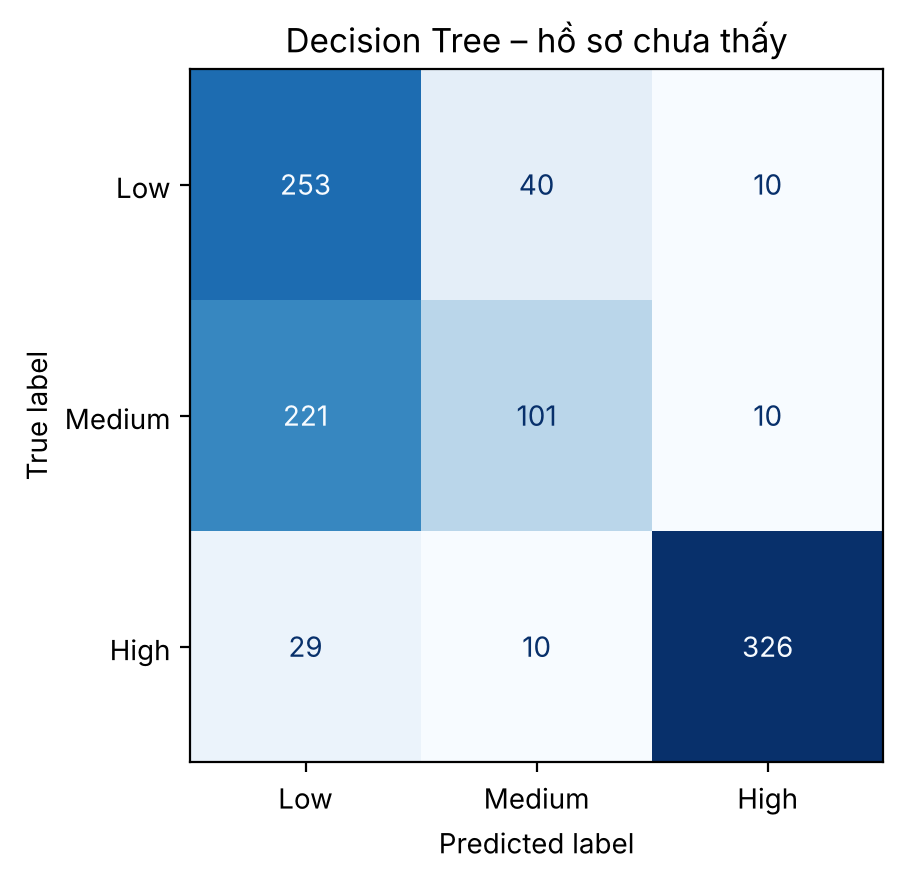

In [5]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay.from_predictions(y, oof["Decision Tree (mô hình trong app)"],
                                        labels=["Low", "Medium", "High"], cmap="Blues",
                                        ax=ax, colorbar=False)
ax.set_title("Decision Tree – hồ sơ chưa thấy")
plt.tight_layout()
plt.show()

## 4. Mô hình dựa vào chỉ số nào

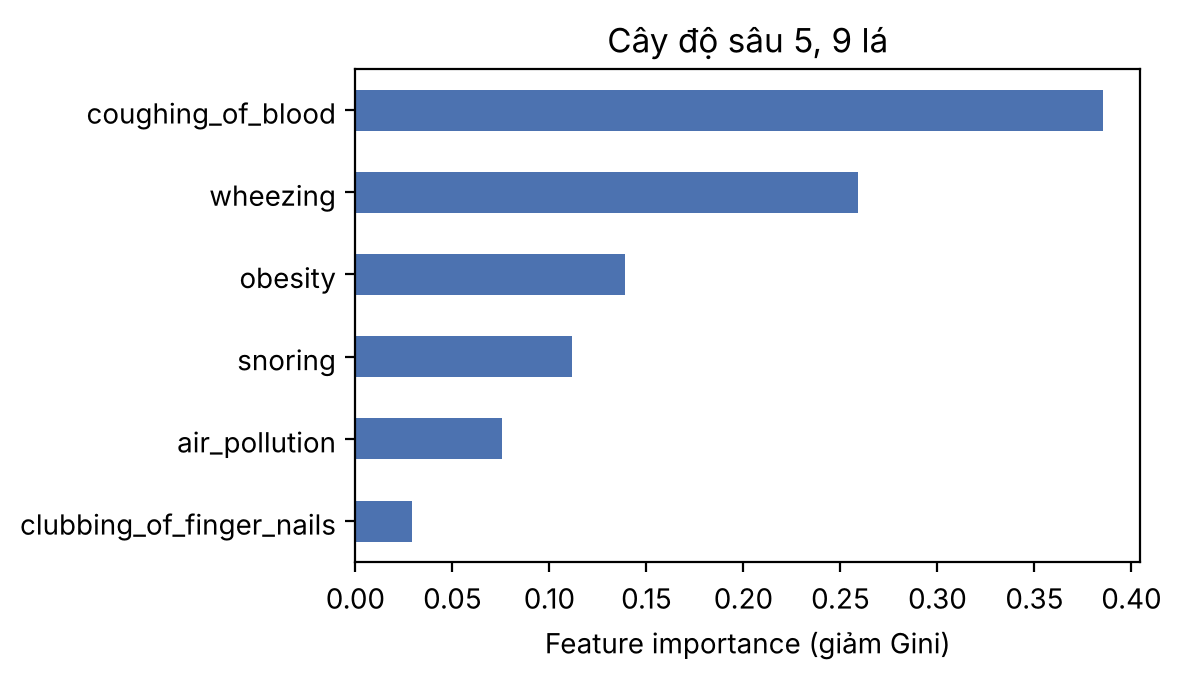

In [6]:
full_tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X, y)
importance = pd.Series(full_tree.feature_importances_, index=FEATURES).sort_values()
importance = importance[importance > 0]
ax = importance.plot.barh(figsize=(6, 3.5), color="#4C72B0")
ax.set_xlabel("Feature importance (giảm Gini)")
ax.set_title(f"Cây độ sâu {full_tree.get_depth()}, {full_tree.get_n_leaves()} lá")
plt.tight_layout()
plt.show()

## 5. Kết luận

- **Chia ngẫu nhiên cho kết quả ảo:** accuracy 100% vì 1.000 dòng chỉ có 53 hồ sơ khác nhau, mọi dòng test đều đã có trong train.
- **Với hồ sơ chưa thấy,** Decision Tree đạt accuracy khoảng 0,75 (F1-macro 0,74), dao động ±0,07 giữa các lần chia. Con số này cao hơn nhiều mốc đoán lớp đông nhất (0,37) nhưng xa 100%.
- **Lỗi tập trung ở lớp Medium:** mô hình nhận ra High tốt nhưng phần lớn ca Medium bị dự đoán thành Low.
- **Logistic Regression đạt khoảng 0,87** với cùng cách đánh giá. Với ít hồ sơ như vậy, mô hình tuyến tính tổng quát hóa tốt hơn cây quyết định; nếu phát triển tiếp nên cân nhắc thay model trong app.
- **Giới hạn:** chỉ 53 hồ sơ nên mọi con số đều có sai số lớn. Dữ liệu phục vụ minh họa kỹ thuật; ứng dụng không dùng để chẩn đoán thật.